In [22]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import descr

In [23]:
opens = np.load("X/train_X.npy")

In [24]:
cum_avg = np.cumsum(opens, axis=0)/np.arange(1, opens.shape[0]+1).reshape(-1, 1)

In [25]:
Y = cum_avg.flatten(order='F')
X = np.arange(len(Y)) % len(cum_avg)

In [26]:
Y_cols = Y.reshape(len(cum_avg), -1, order='F')
X_cols = X.reshape(len(cum_avg), -1, order='F')

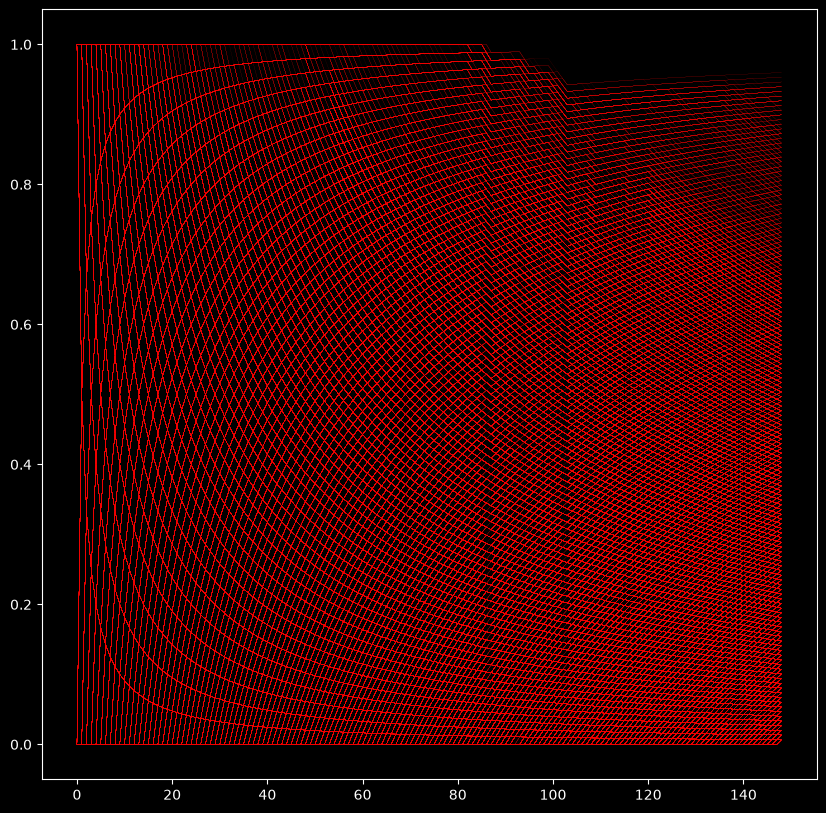

In [43]:
plt.figure(figsize=(10,10))
plt.plot(X_cols, Y_cols, color = "red", linewidth=0.05)
plt.show()

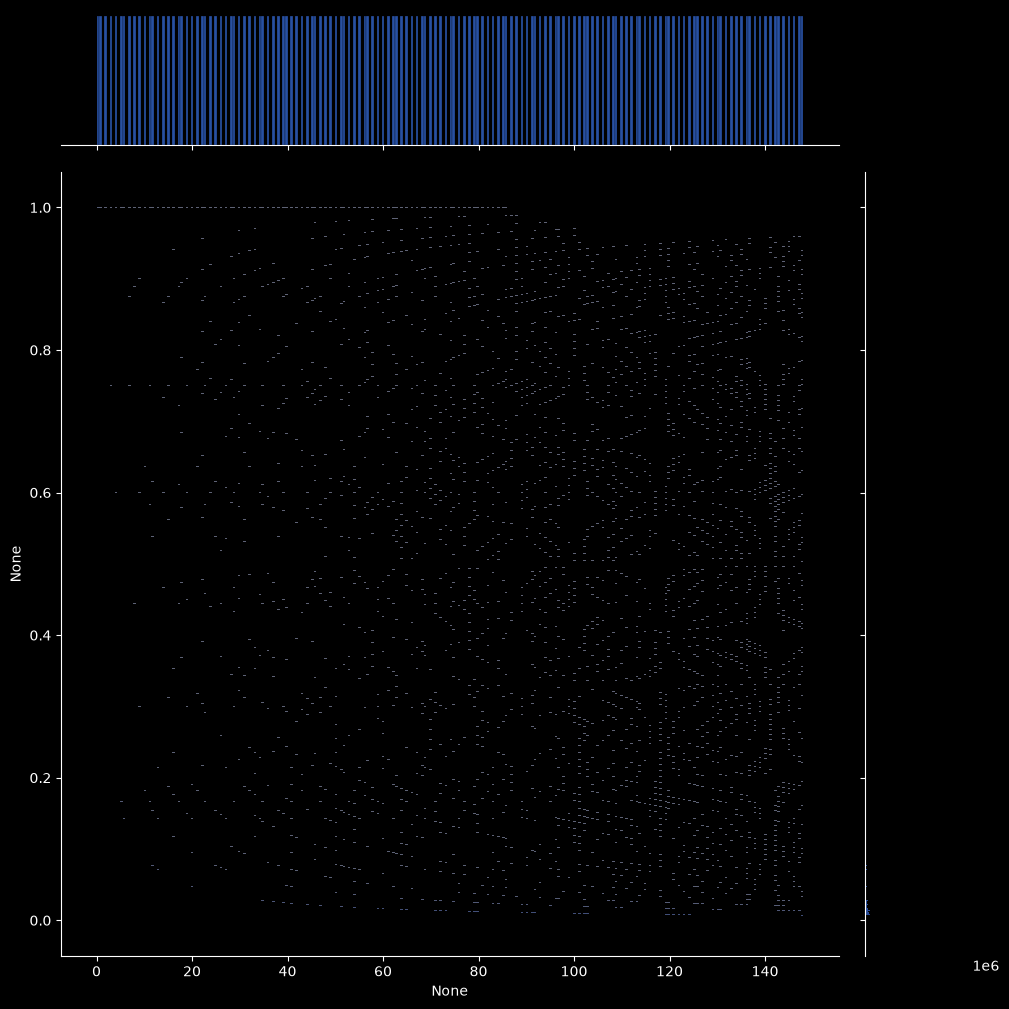

In [28]:
sns.jointplot(x=X,y=Y, kind="hist", alpha=0.5, height = 10)

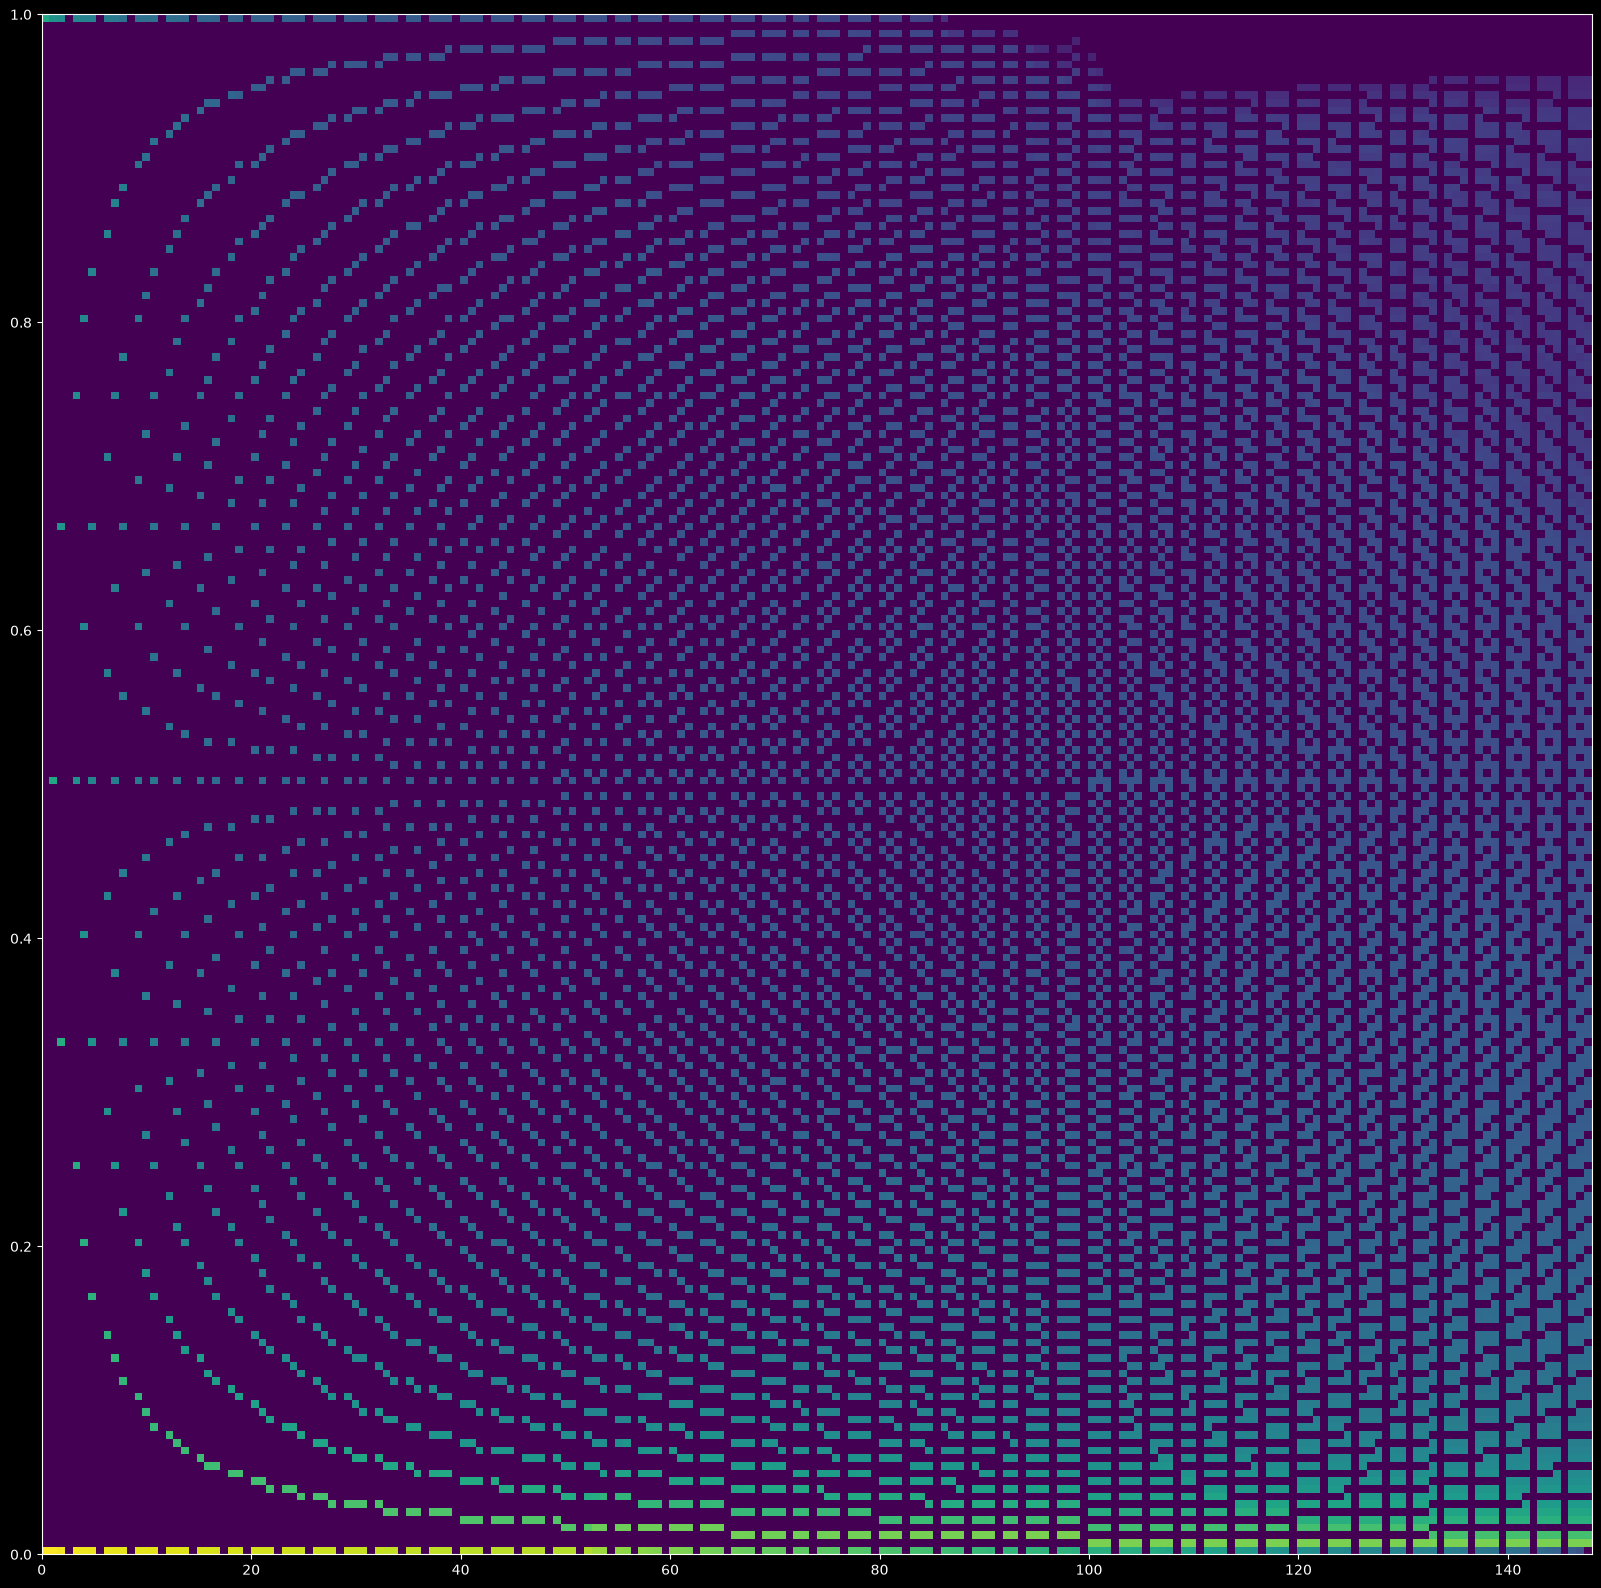

In [29]:
from matplotlib.colors import LogNorm, PowerNorm

plt.figure(figsize=(20,20))
plt.hist2d(x=X,y=Y, bins=200, norm=PowerNorm(gamma=0.2))
plt.show()

In [30]:
max_pos_change_idx = (Y_cols[-1, :] - Y_cols[0, :]).argmax()
max_neg_change_idx = (Y_cols[0, :] - Y_cols[-1, :]).argmax()

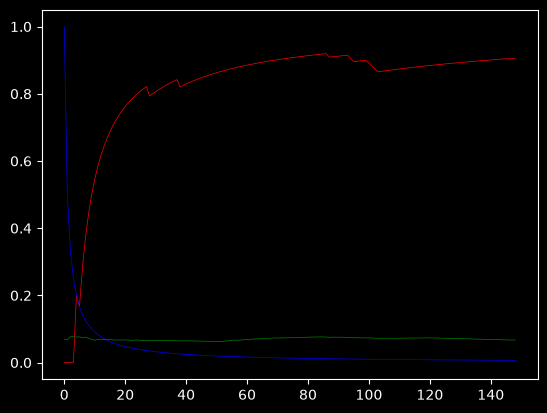

In [31]:
plt.plot(X_cols[:, max_pos_change_idx], Y_cols[:, max_pos_change_idx], color = "red", linewidth=0.5)
plt.plot(X_cols[:, max_neg_change_idx], Y_cols[:, max_neg_change_idx], color = "blue", linewidth=0.5)
plt.plot(X_cols.mean(axis=1), Y_cols.mean(axis=1), color = "green", linewidth=0.5)

In [32]:
filter_increase  = (Y_cols[-1, :] - Y_cols[50, :]) > 0.3
filter_decrease  = (Y_cols[50, :] - Y_cols[-1, :]) > 0.3

Y_incraese = Y_cols[:, filter_increase]
X_increase = X_cols[:, filter_increase]

Y_decrease = Y_cols[:, filter_decrease]
X_decrease = X_cols[:, filter_decrease]

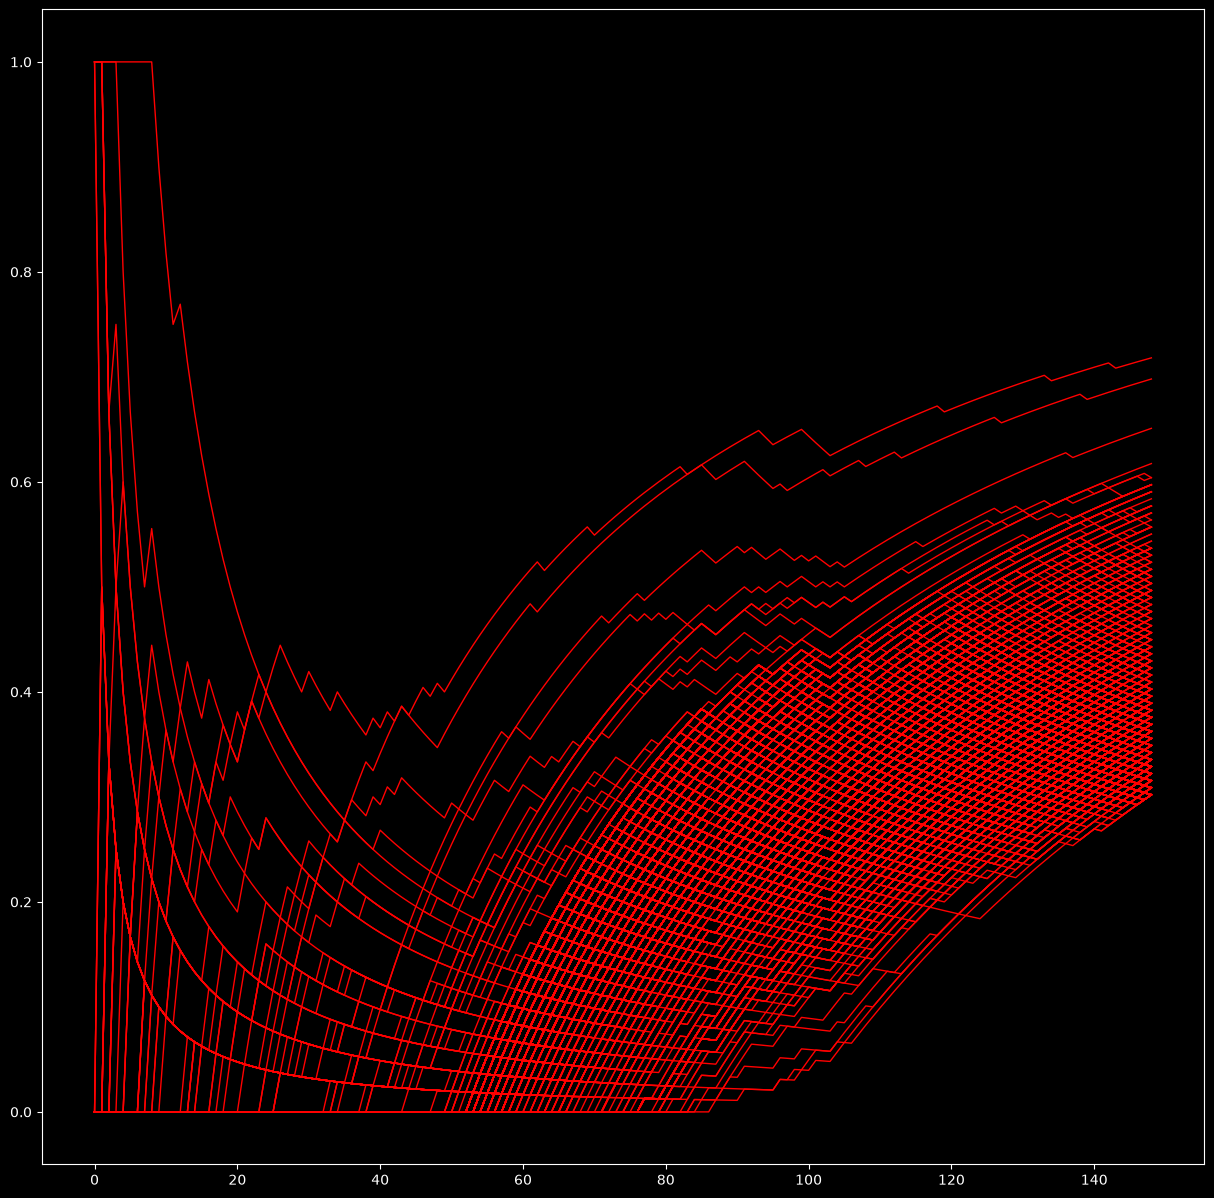

In [37]:
plt.figure(figsize=(15,15))
plt.plot(X_increase, Y_incraese, color = "red", linewidth=1)
plt.show()

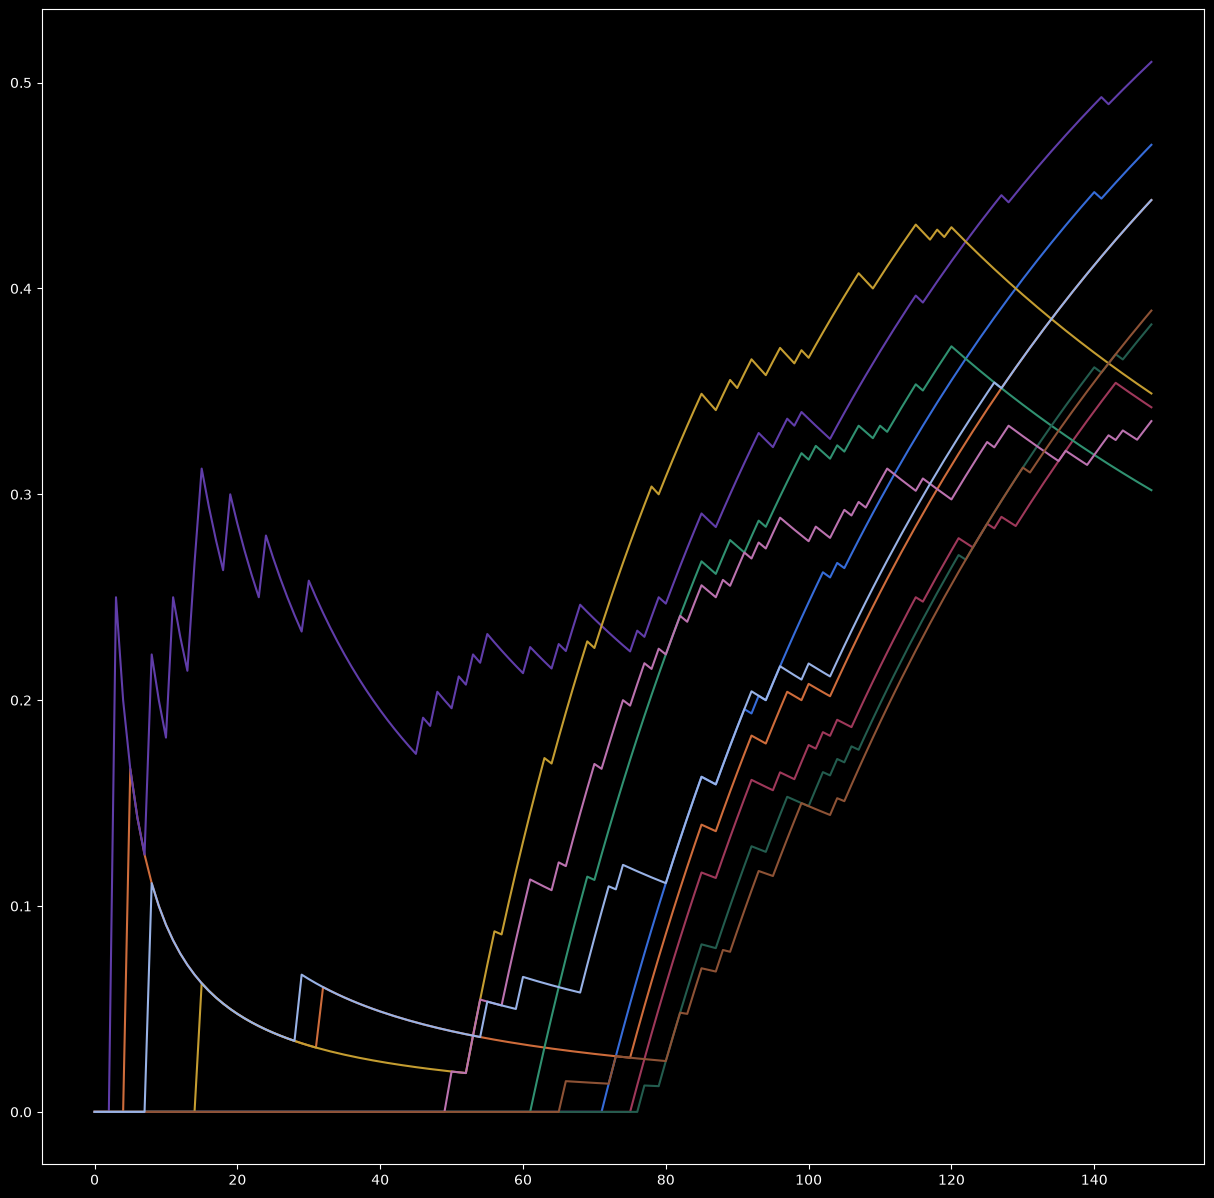

In [38]:
plt.figure(figsize=(15,15))
plt.plot(X_increase[:, :10], Y_incraese[:, :10])
plt.show()

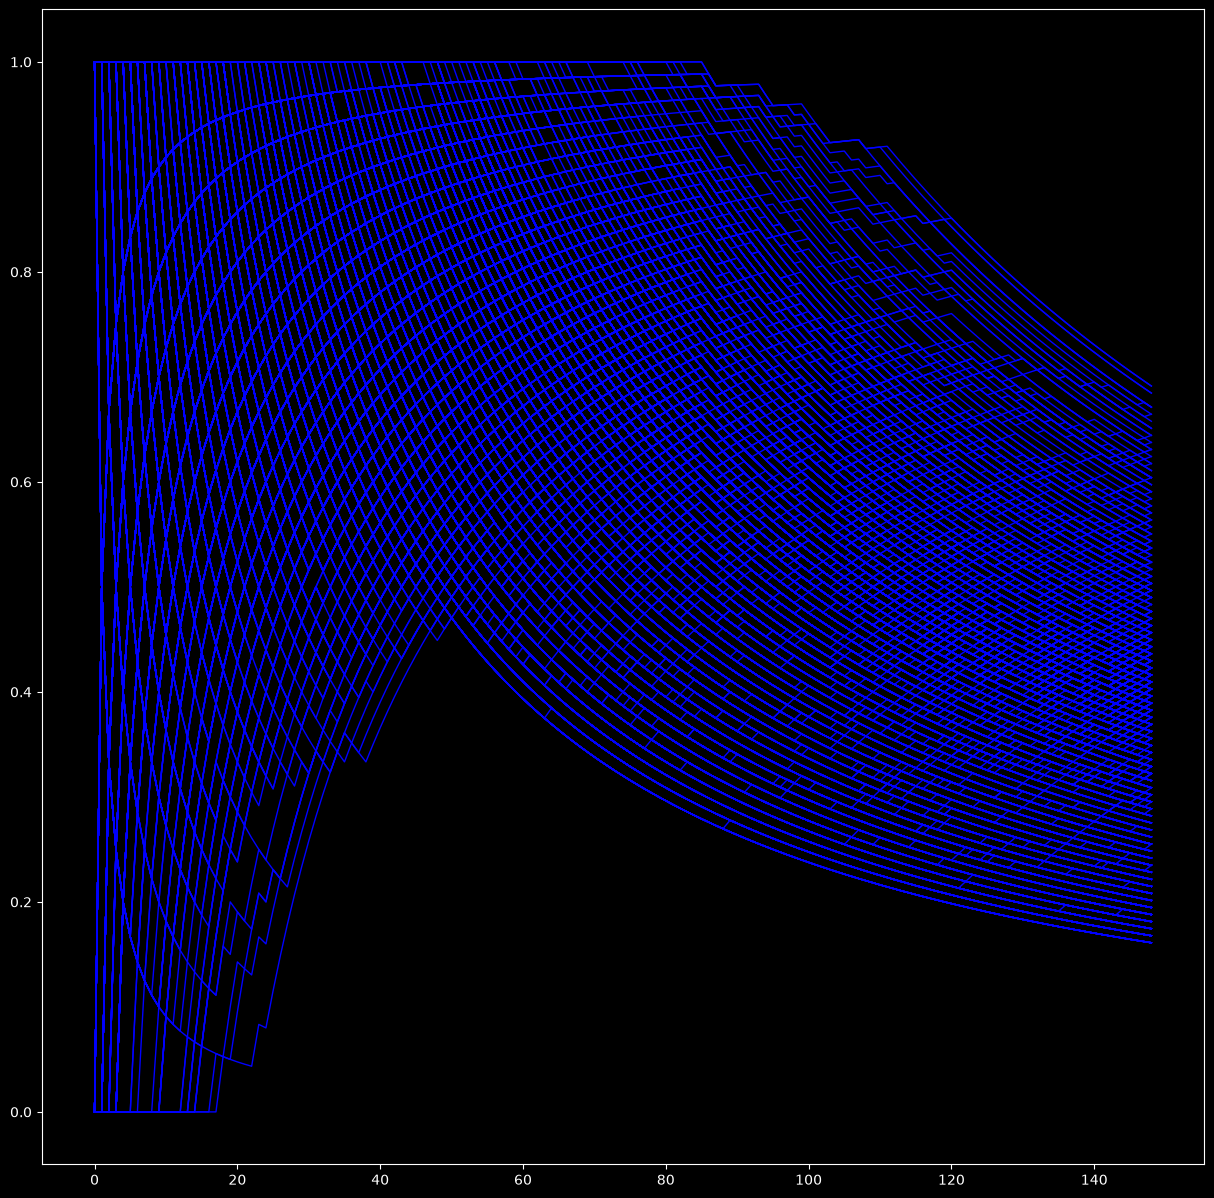

In [39]:
plt.figure(figsize=(15,15))
plt.plot(X_decrease, Y_decrease, color = "blue", linewidth=1)
plt.show()

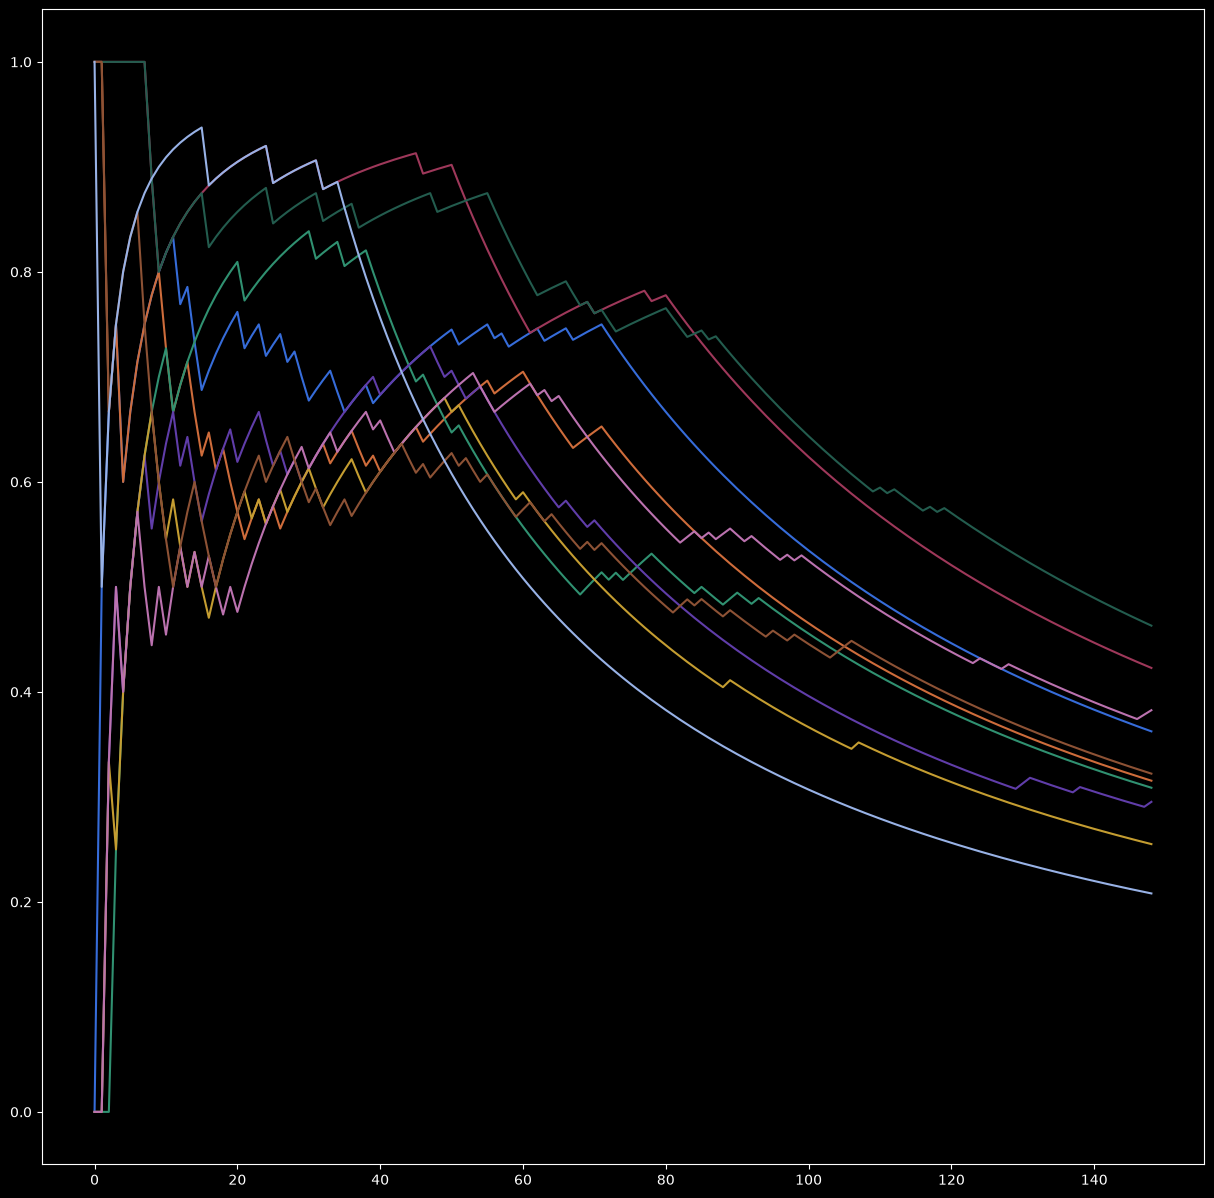

In [40]:
plt.figure(figsize=(15,15))
plt.plot(X_decrease[:, :10], Y_decrease[:, :10])
plt.show()